# GBSG: exploratory survival analysis

**Input:** `gbsg.csv` in the same directory as this notebook. The requested name
`gbsv.csv` appears to refer to this file: it has 686 patient records and the
variables in the German Breast Cancer Study Group (GBSG) dataset.

This notebook inspects data quality and patient characteristics, estimate recurrence-free
survival with Kaplan–Meier curves, fit an adjusted Cox proportional hazards model,
and examine its assumptions. The endpoint combines **recurrence or death**; this
file cannot separate those two types of event.

## Setup and reproducibility

In [ ]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import chi2, norm
from patsy import dmatrix, build_design_matrices
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.duration.hazard_regression import PHReg
from statsmodels.nonparametric.smoothers_lowess import lowess

DATA_PATH = Path('gbsg.csv')  # Change this if you move the data file.

Python: 3.12.7
CSV: /Users/macbookair/Desktop/BIOF3001/gbsg.csv
SHA-256: 5d1513d9ffc4008788ee624605480c6835b88f14af2dbf31991ae4f802817e47


,Installed version
numpy,1.26.4
pandas,2.2.3
matplotlib,3.9.2
scipy,1.13.1
patsy,0.5.6
statsmodels,0.14.5


## Load Data

In [2]:
raw = pd.read_csv(DATA_PATH)
expected = ['pid', 'age', 'meno', 'size', 'grade', 'nodes', 'pgr', 'er',
            'hormon', 'rfstime', 'status']
exported_index = [c for c in raw.columns if c.startswith('Unnamed:')]
for column in exported_index:
    if not np.array_equal(raw[column].to_numpy(), np.arange(1, len(raw) + 1)):
        raise ValueError(f'{column} is not the expected exported row index; inspect it.')
df = raw.drop(columns=exported_index).copy()
if set(df.columns) != set(expected):
    raise ValueError(f'Unexpected schema: {list(df.columns)}')
df = df[expected]
print(f'{len(df):,} patients; {df.shape[1]} analytical columns.')
print('Removed exported index columns:', exported_index)
display(df.head(8))

686 patients; 11 analytical columns.
Removed exported index columns: ['Unnamed: 0']


,pid,age,meno,size,grade,nodes,pgr,er,hormon,rfstime,status
0,132,49,0,18,2,2,0,0,0,1838,0
1,1575,55,1,20,3,16,0,0,0,403,1
2,1140,56,1,40,3,3,0,0,0,1603,0
3,769,45,0,25,3,1,0,4,0,177,0
4,130,65,1,30,2,5,0,36,1,1855,0
5,1642,48,0,52,2,11,0,0,0,842,1
6,475,48,0,21,3,8,0,0,0,293,1
7,973,37,0,20,2,9,0,0,1,42,0


## Data quality

We check missingness, finite numeric values, patient uniqueness, allowed category
codes, and basic ranges before fitting. No rows are silently deleted or imputed.
Large values are retained: a long right tail alone is not evidence of an error.

In [ ]:
quality = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'unique': df.nunique(),
    'minimum': df.min(),
    'maximum': df.max(),
})
display(quality)

,dtype,missing,unique,minimum,maximum
pid,int64,0,686,1,1819
age,int64,0,54,21,80
meno,int64,0,2,0,1
size,int64,0,58,3,120
grade,int64,0,3,1,3
nodes,int64,0,30,1,51
pgr,int64,0,242,0,2380
er,int64,0,244,0,1144
hormon,int64,0,2,0,1
rfstime,int64,0,574,8,2659


,Pass
No missing values,True
All values numeric and finite,True
One record per patient,True
No duplicate complete records,True
Positive follow-up durations,True
Binary event indicator,True
Binary menopausal and therapy codes,True
"Grade in 1, 2, 3",True
Positive age and tumour size,True
At least one positive node,True


In [4]:
n = len(df)
events = int(df.status.sum())
cohort_summary = pd.Series({
    'Patients': n,
    'Observed recurrence/death events': events,
    'Right-censored patients': n - events,
    'Observed event fraction (%)': 100 * events / n,
    'Median age (years)': df.age.median(),
    'Median observed duration (days)': df.rfstime.median(),
    'Minimum observed duration (days)': df.rfstime.min(),
    'Maximum observed duration (days)': df.rfstime.max(),
}, name='Value')
display(cohort_summary.to_frame().round(2))

,Value
Patients,686.00
Observed recurrence/death events,299.00
Right-censored patients,387.00
Observed event fraction (%),43.59
Median age (years),53.00
Median observed duration (days),1084.00
Minimum observed duration (days),8.00
Maximum observed duration (days),2659.00


The observed event fraction is a description of this file, **not** the probability
of an event by a fixed time. Patients have different follow-up durations, and
censored patients may have events later. Similarly, the median recorded duration
is not median recurrence-free survival. We estimate survival using censoring-aware
methods below.

## Patient characteristics and distributions

Grade is treated as a category, avoiding an assumption that the change from grade
1 to 2 has the same effect as the change from 2 to 3. Receptor values of zero are
retained as observed measurements.

,count,mean,std,min,25%,50%,75%,max
age,686.0,53.05,10.12,21.0,46.0,53.0,61.00,80.0
size,686.0,29.33,14.30,3.0,20.0,25.0,35.00,120.0
nodes,686.0,5.01,5.48,1.0,1.0,3.0,7.00,51.0
pgr,686.0,110.00,202.33,0.0,7.0,32.5,131.75,2380.0
er,686.0,96.25,153.08,0.0,8.0,36.0,114.00,1144.0


,Variable,Category,n,%
0,meno,Premenopausal,290,42.3
1,meno,Postmenopausal,396,57.7
2,grade,Grade 1,81,11.8
3,grade,Grade 2,444,64.7
4,grade,Grade 3,161,23.5
5,hormon,No hormonal therapy,440,64.1
6,hormon,Hormonal therapy,246,35.9


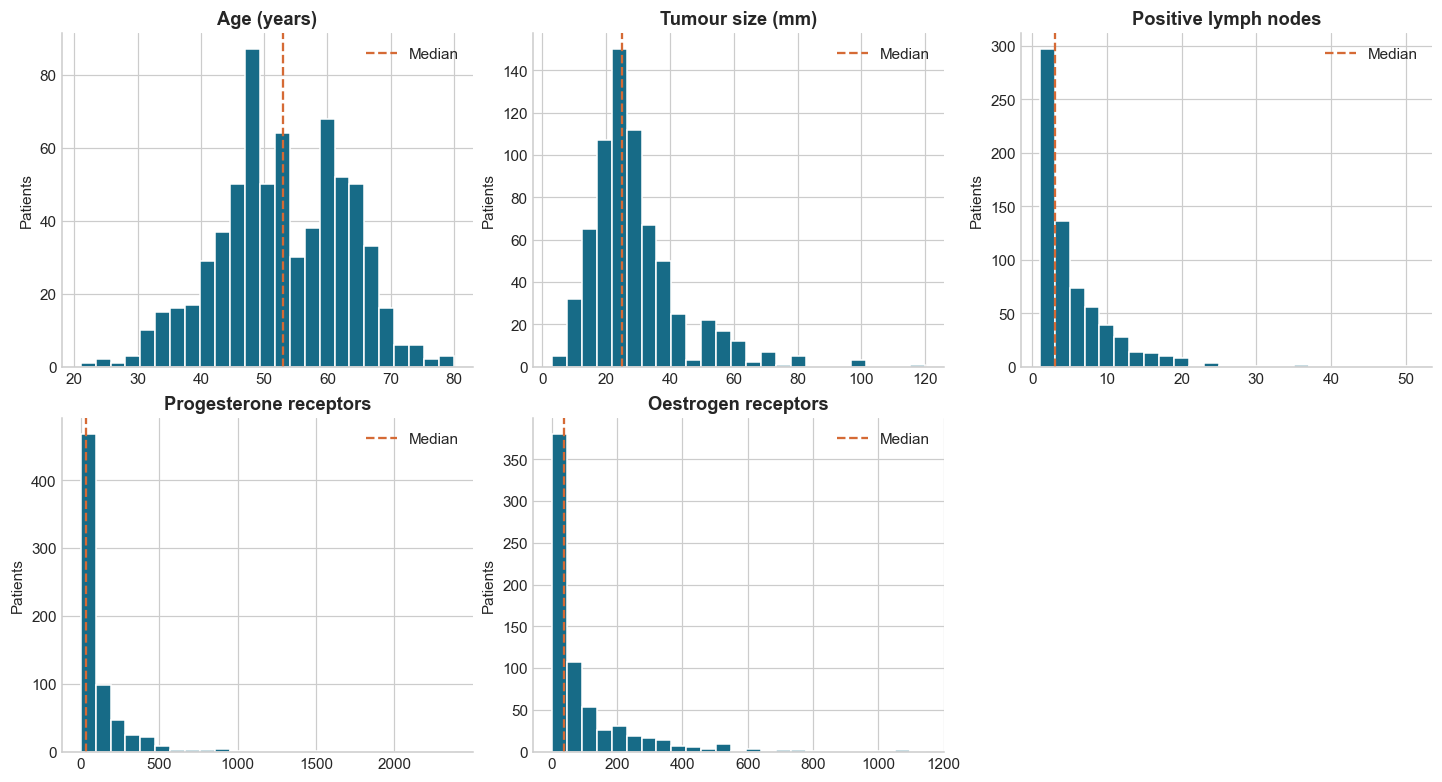

In [5]:
continuous = ['age', 'size', 'nodes', 'pgr', 'er']
display(df[continuous].describe(percentiles=[0.25, 0.5, 0.75]).T.round(2))
category_maps = {
    'meno': {0: 'Premenopausal', 1: 'Postmenopausal'},
    'grade': {1: 'Grade 1', 2: 'Grade 2', 3: 'Grade 3'},
    'hormon': {0: 'No hormonal therapy', 1: 'Hormonal therapy'},
}
category_rows = []
for column, mapping in category_maps.items():
    for value, label in mapping.items():
        count = int(df[column].eq(value).sum())
        category_rows.append([column, label, count, 100 * count / n])
display(pd.DataFrame(category_rows, columns=['Variable', 'Category', 'n', '%']).round(1))

fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
labels = {'age': 'Age (years)', 'size': 'Tumour size (mm)',
          'nodes': 'Positive lymph nodes', 'pgr': 'Progesterone receptors',
          'er': 'Oestrogen receptors'}
for ax, column in zip(axes.flat, continuous):
    ax.hist(df[column], bins=25, color='#176B87', edgecolor='white')
    ax.axvline(df[column].median(), color='#D56A35', linestyle='--', label='Median')
    ax.set(title=labels[column], ylabel='Patients')
    ax.legend(frameon=False)
axes.flat[-1].axis('off')
plt.show()

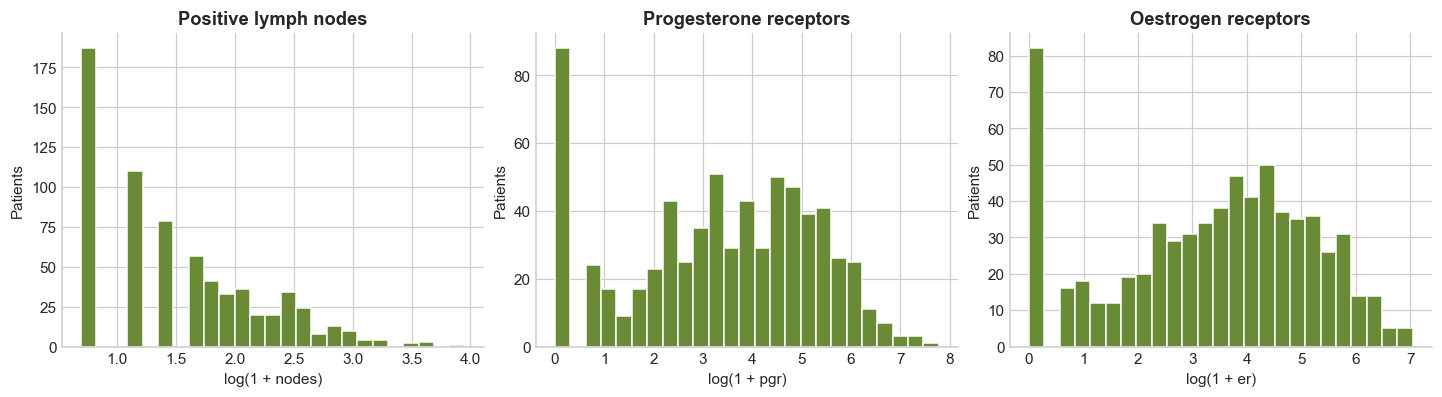

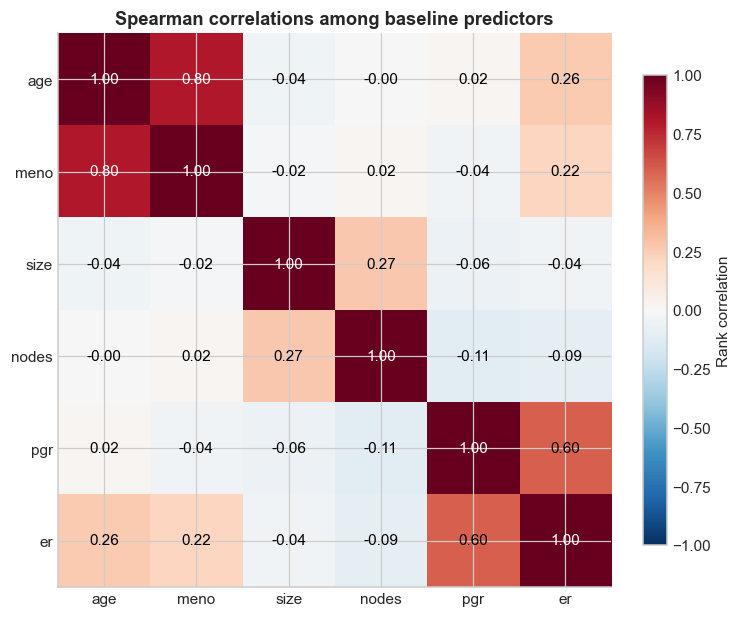

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
for ax, column in zip(axes, ['nodes', 'pgr', 'er']):
    # log1p includes observed zeros without adding arbitrary missing-value codes.
    ax.hist(np.log1p(df[column]), bins=25, color='#698B35', edgecolor='white')
    ax.set(title=labels[column], xlabel=f'log(1 + {column})', ylabel='Patients')
plt.show()

corr_columns = ['age', 'meno', 'size', 'nodes', 'pgr', 'er']
corr = df[corr_columns].corr(method='spearman')
fig, ax = plt.subplots(figsize=(7, 5.5), constrained_layout=True)
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns)
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center',
                color='white' if abs(corr.iloc[i, j]) > 0.65 else 'black')
ax.set_title('Spearman correlations among baseline predictors')
fig.colorbar(im, ax=ax, shrink=0.85, label='Rank correlation')
plt.show()

The log-scale views make skewed predictors easier to inspect. The model uses
logarithms for node counts and receptor levels, with the exact interpretation
given below. Correlations can flag overlapping information (for example age and
menopausal status), but do not establish causation. Patient ID and the outcome
duration are excluded from this predictor-correlation plot.

## 5. Follow-up and overall Kaplan–Meier survival

Kaplan–Meier estimates the probability of remaining alive without recurrence.
Censored patients contribute to risk sets up to their censoring time. The shaded
region is a **pointwise 95% confidence interval**, using Greenwood standard errors
and a log–log transformation; it is not a simultaneous confidence band.

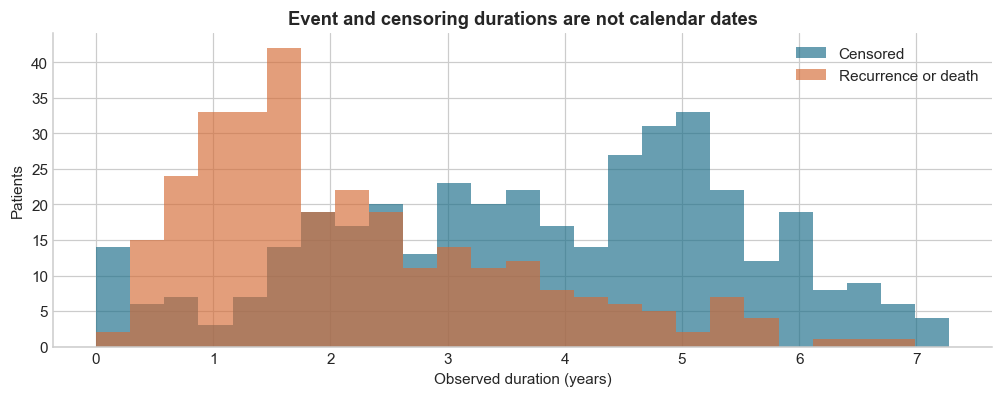

Reverse KM median follow-up: 1645 days (4.50 years)
KM median recurrence-free survival: 1807 days (4.95 years)
95% CI for median (days): (1528, 2018)


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5), constrained_layout=True)
bins = np.linspace(0, df.rfstime.max(), 26)
for status, label, color in [(0, 'Censored', '#176B87'),
                              (1, 'Recurrence or death', '#D56A35')]:
    ax.hist(df.loc[df.status.eq(status), 'rfstime'] / 365.25,
            bins=bins / 365.25, alpha=0.65, label=label, color=color)
ax.set(xlabel='Observed duration (years)', ylabel='Patients',
       title='Event and censoring durations are not calendar dates')
ax.legend(frameon=False)
plt.show()

km = SurvfuncRight(df.rfstime, df.status)
reverse_km = SurvfuncRight(df.rfstime, 1 - df.status)
print(f'Reverse KM median follow-up: {reverse_km.quantile(0.5):.0f} days '
      f'({reverse_km.quantile(0.5) / 365.25:.2f} years)')
median_rfs = km.quantile(0.5)
if np.isfinite(median_rfs):
    print(f'KM median recurrence-free survival: {median_rfs:.0f} days '
          f'({median_rfs / 365.25:.2f} years)')
    print('95% CI for median (days):', km.quantile_ci(0.5))
else:
    print('KM median recurrence-free survival was not reached during observation.')

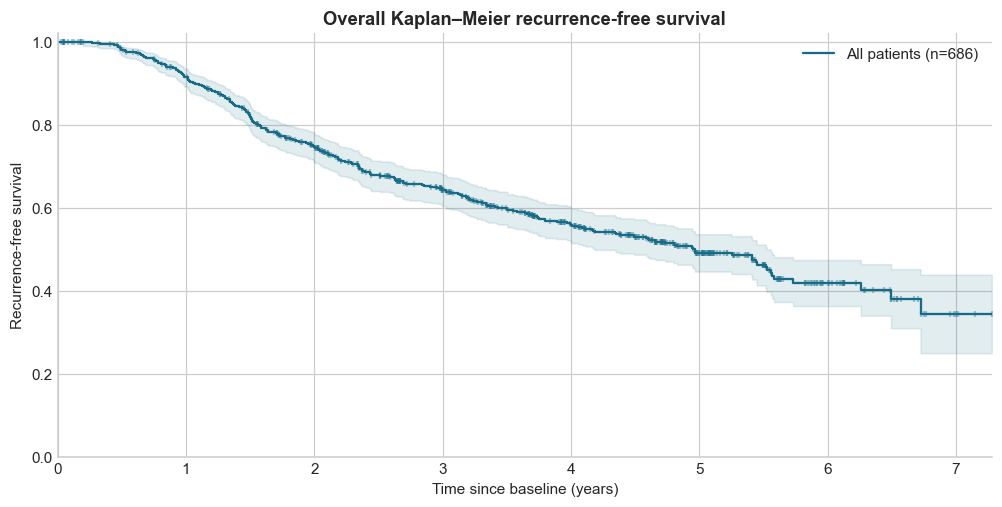

,Year,Survival,95% lower,95% upper,At risk just before time
0,1,0.916,0.892,0.934,602
1,3,0.643,0.603,0.679,331
2,5,0.492,0.446,0.536,121


,Year,At risk just before time
0,0,686
1,1,602
2,2,458
3,3,331
4,4,228
5,5,121
6,6,36
7,7,3


In [8]:
def loglog_ci(survival, standard_error, alpha=0.05):
    """Pointwise log-log CI from KM survival estimates and Greenwood SEs."""
    survival = np.asarray(survival, dtype=float)
    standard_error = np.asarray(standard_error, dtype=float)
    lower, upper = survival.copy(), survival.copy()
    inside = (survival > 0) & (survival < 1)
    s = survival[inside]
    theta = np.log(-np.log(s))
    theta_se = standard_error[inside] / np.abs(s * np.log(s))
    z = norm.ppf(1 - alpha / 2)
    lower[inside] = np.exp(-np.exp(theta + z * theta_se))
    upper[inside] = np.exp(-np.exp(theta - z * theta_se))
    return lower, upper


def km_at(sf, days):
    """Right-continuous KM estimate and pointwise CI at specified durations."""
    days = np.atleast_1d(days).astype(float)
    index = np.searchsorted(sf.surv_times, days, side='right')
    survival = np.r_[1.0, sf.surv_prob][index]
    se = np.r_[0.0, sf.surv_prob_se][index]
    lower, upper = loglog_ci(survival, se)
    return survival, lower, upper


def plot_km(ax, data, label, color, confidence=True):
    sf = SurvfuncRight(data.rfstime, data.status)
    times = np.r_[0.0, sf.surv_times, data.rfstime.max()]
    survival = np.r_[1.0, sf.surv_prob, sf.surv_prob[-1]]
    lower, upper = loglog_ci(sf.surv_prob, sf.surv_prob_se)
    ax.step(times / 365.25, survival, where='post', label=label, color=color)
    if confidence:
        ax.fill_between(times / 365.25, np.r_[1.0, lower, lower[-1]],
                        np.r_[1.0, upper, upper[-1]], step='post',
                        color=color, alpha=0.12)
    censored = data.loc[data.status.eq(0), 'rfstime'].to_numpy()
    ax.scatter(censored / 365.25, km_at(sf, censored)[0], marker='|',
               color=color, alpha=0.35, s=20)
    ax.set(xlabel='Time since baseline (years)', ylabel='Recurrence-free survival',
           ylim=(0, 1.02), xlim=(0, df.rfstime.max() / 365.25))
    return sf


fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
plot_km(ax, df, f'All patients (n={n})', '#176B87')
ax.set_title('Overall Kaplan–Meier recurrence-free survival')
ax.legend(frameon=False)
plt.show()

years = np.array([1, 3, 5])
days = years * 365.25
survival, lower, upper = km_at(km, days)
survival_at_times = pd.DataFrame({
    'Year': years, 'Survival': survival, '95% lower': lower, '95% upper': upper,
    'At risk just before time': [int(df.rfstime.ge(t).sum()) for t in days],
})
display(survival_at_times.round(3))
risk_years = np.arange(0, 8)
risk_years = risk_years[risk_years * 365.25 <= df.rfstime.max()]
display(pd.DataFrame({'Year': risk_years,
                      'At risk just before time': [int(df.rfstime.ge(y * 365.25).sum())
                                                   for y in risk_years]}))

## 6. Unadjusted group comparisons

Compare curves by therapy, grade, and menopausal status. These are descriptive
comparisons; a visible difference is not an adjusted treatment effect. The
log-rank tests are exploratory omnibus tests for each grouping, with no
multiple-comparison correction. A nonsignificant result does not establish that
groups have the same survival.

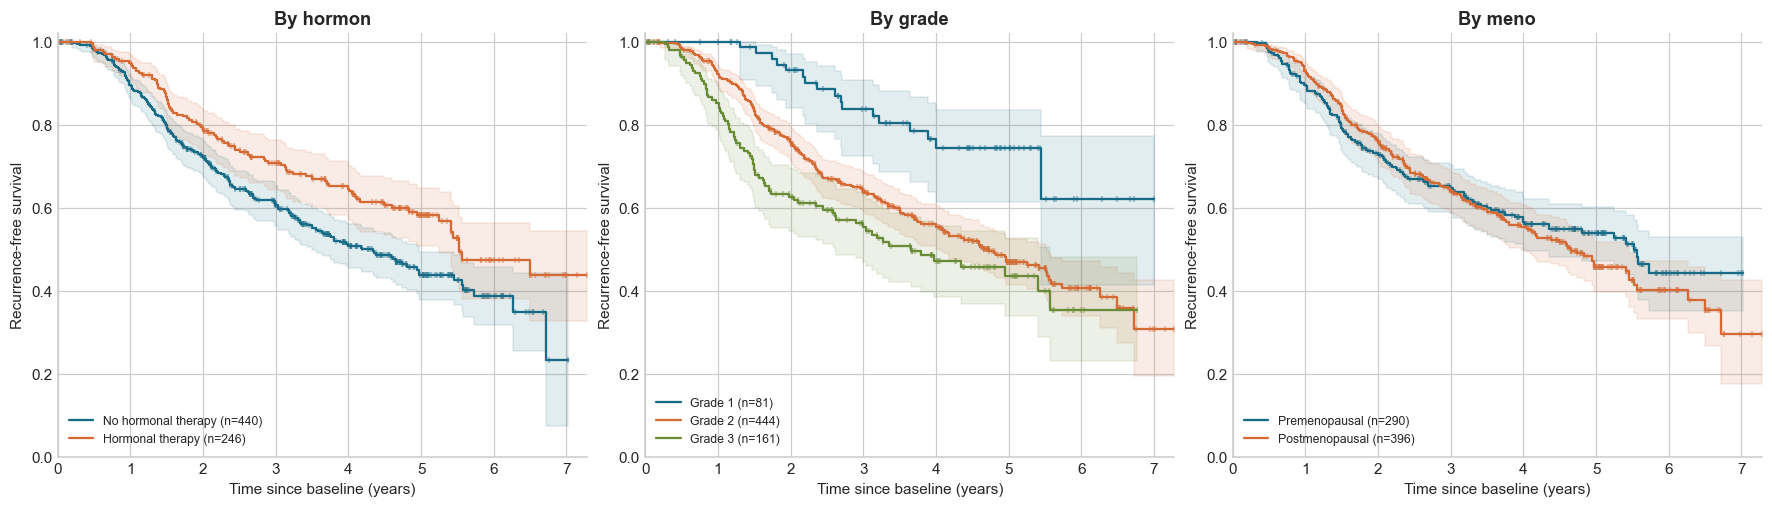

,Grouping,Group,Patients,Events,Censored,5-year KM,95% lower,95% upper
0,hormon,No hormonal therapy,440,205,235,0.437,0.378,0.494
1,hormon,Hormonal therapy,246,94,152,0.581,0.507,0.648
2,grade,Grade 1,81,18,63,0.744,0.614,0.836
3,grade,Grade 2,444,202,242,0.470,0.413,0.524
4,grade,Grade 3,161,79,82,0.435,0.339,0.527
5,meno,Premenopausal,290,119,171,0.539,0.471,0.602
6,meno,Postmenopausal,396,180,216,0.458,0.396,0.517


,Grouping,Group,Year 0,Year 1,Year 3,Year 5,Year 7
0,hormon,No hormonal therapy,440,379,195,63,1
1,hormon,Hormonal therapy,246,223,136,58,2
2,grade,Grade 1,81,77,51,21,0
3,grade,Grade 2,444,392,218,81,3
4,grade,Grade 3,161,133,62,19,0
5,meno,Premenopausal,290,245,140,56,1
6,meno,Postmenopausal,396,357,191,65,2


,Grouping,Chi-square,df,Exploratory p
0,hormon,8.5648,1,0.0034
1,grade,21.0944,2,0.0000
2,meno,0.2802,1,0.5966


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
group_summaries, logrank_rows, risk_rows = [], [], []
colors = ['#176B87', '#D56A35', '#698B35']
for ax, column in zip(axes, ['hormon', 'grade', 'meno']):
    for (value, label), color in zip(category_maps[column].items(), colors):
        group = df.loc[df[column].eq(value)]
        sf = plot_km(ax, group, f'{label} (n={len(group)})', color)
        s5, lo5, hi5 = km_at(sf, [5 * 365.25])
        supported = group.rfstime.max() >= 5 * 365.25
        group_summaries.append({
            'Grouping': column, 'Group': label, 'Patients': len(group),
            'Events': int(group.status.sum()),
            'Censored': int(group.status.eq(0).sum()),
            '5-year KM': s5[0] if supported else np.nan,
            '95% lower': lo5[0] if supported else np.nan,
            '95% upper': hi5[0] if supported else np.nan,
        })
        risk_rows.append({'Grouping': column, 'Group': label,
                          **{f'Year {y}': int(group.rfstime.ge(y * 365.25).sum())
                             for y in [0, 1, 3, 5, 7]}})
    statistic, pvalue = survdiff(df.rfstime, df.status, df[column])
    logrank_rows.append({'Grouping': column, 'Chi-square': statistic,
                         'df': df[column].nunique() - 1, 'Exploratory p': pvalue})
    ax.set_title(f'By {column}')
    ax.legend(frameon=False, fontsize=8, loc='lower left')
plt.show()
display(pd.DataFrame(group_summaries).round(3))
display(pd.DataFrame(risk_rows))
display(pd.DataFrame(logrank_rows).round(4))

## 7. Adjusted Cox proportional hazards model

We include all eight baseline predictor concepts without selecting variables by
their p-values. Grade contributes two indicator terms (reference = grade 1).
Efron's method handles tied event times. There is no intercept: the baseline
hazard absorbs it.

| Term | HR comparison |
|---|---|
| Age | 10 years older |
| Tumour size | 10 mm larger |
| Positive nodes | Twice as many positive nodes |
| Progesterone receptor | Doubling of `pgr + 1` |
| Oestrogen receptor | Doubling of `er + 1` |
| Menopausal status | Postmenopausal versus premenopausal |
| Hormonal therapy | Yes versus no |
| Grade | Grade 2 or 3 versus grade 1 |

In [10]:
model_data = df.assign(
    age10=df.age / 10,
    size10=df['size'] / 10,
    log2_nodes=np.log2(df.nodes),
    log2_pgr1=np.log2(df.pgr + 1),
    log2_er1=np.log2(df.er + 1),
)
formula = ('age10 + meno + size10 + C(grade, Treatment(reference=1)) + '
           'log2_nodes + log2_pgr1 + log2_er1 + hormon')
design = dmatrix(formula, model_data, return_type='dataframe', NA_action='raise')
X = design.drop(columns='Intercept')
if np.linalg.matrix_rank(X.to_numpy()) != X.shape[1]:
    raise ValueError('The design matrix is not full rank.')

cox = PHReg(model_data.rfstime, X, status=model_data.status,
            ties='efron', missing='raise')
fit = cox.fit(disp=0, maxiter=200, tol=1e-9)
score_max = float(np.max(np.abs(cox.score(fit.params))))
if not np.isfinite(fit.params).all() or score_max > 1e-5:
    raise RuntimeError(f'Check model convergence: max absolute score = {score_max}')
print(f'{len(model_data)} patients; {events} events; {X.shape[1]} coefficients.')
first_event = model_data.loc[model_data.status.eq(1), 'rfstime'].min()
early_censored = int((model_data.status.eq(0) & model_data.rfstime.lt(first_event)).sum())
print(f'First event: day {first_event}; {early_censored} patients were censored earlier.')
print(f'statsmodels reports {cox.surv.n_obs} contributing patients: the earlier-censored '
      'patients enter no event-time risk set and contribute no Cox partial likelihood. '
      'All patients remain in the descriptive and Kaplan–Meier analyses.')
print(f'Maximum absolute likelihood score at solution: {score_max:.2e}')
print(fit.summary())

term_labels = {
    'age10': 'Age: +10 years', 'meno': 'Post- vs premenopausal',
    'size10': 'Tumour size: +10 mm',
    'C(grade, Treatment(reference=1))[T.2]': 'Grade 2 vs grade 1',
    'C(grade, Treatment(reference=1))[T.3]': 'Grade 3 vs grade 1',
    'log2_nodes': 'Positive nodes: doubling',
    'log2_pgr1': 'Progesterone receptor + 1: doubling',
    'log2_er1': 'Oestrogen receptor + 1: doubling',
    'hormon': 'Hormonal therapy: yes vs no',
}
ci = fit.conf_int()
hazard_ratios = pd.DataFrame({
    'Term': X.columns,
    'Comparison': [term_labels.get(c, c) for c in X.columns],
    'HR': np.exp(fit.params), '95% lower': np.exp(ci[:, 0]),
    '95% upper': np.exp(ci[:, 1]), 'p-value': fit.pvalues,
})
display(hazard_ratios.drop(columns='Term').round(4))

686 patients; 299 events; 9 coefficients.
First event: day 72; 14 patients were censored earlier.
statsmodels reports 672 contributing patients: the earlier-censored patients enter no event-time risk set and contribute no Cox partial likelihood. All patients remain in the descriptive and Kaplan–Meier analyses.
Maximum absolute likelihood score at solution: 1.42e-12
                                      Results: PHReg
Model:                               PH Reg                 Sample size:                672
Dependent variable:                  rfstime                Num. events:                299
Ties:                                Efron                                                 
-------------------------------------------------------------------------------------------
                                       log HR log HR SE   HR      t    P>|t|  [0.025 0.975]
-------------------------------------------------------------------------------------------
C(grade, Treatment(referenc

,Comparison,HR,95% lower,95% upper,p-value
0,Grade 2 vs grade 1,1.6840,1.0283,2.7578,0.0384
1,Grade 3 vs grade 1,1.7724,1.0320,3.0439,0.0381
2,Age: +10 years,0.9211,0.7713,1.1001,0.3644
3,Post- vs premenopausal,1.2102,0.8457,1.7320,0.2968
4,Tumour size: +10 mm,1.0418,0.9641,1.1257,0.3009
5,Positive nodes: doubling,1.3987,1.2776,1.5313,0.0000
6,Progesterone receptor + 1: doubling,0.8742,0.8265,0.9247,0.0000
7,Oestrogen receptor + 1: doubling,1.0247,0.9666,1.0863,0.4122
8,Hormonal therapy: yes vs no,0.6802,0.5283,0.8756,0.0028


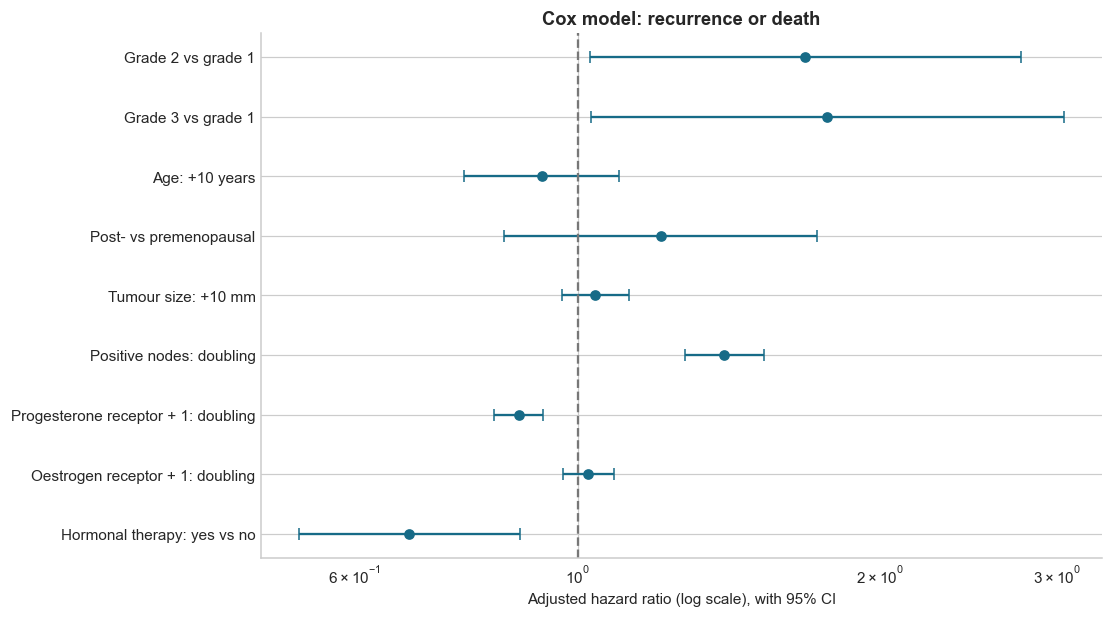

Holding the included covariates fixed, the hormonal-therapy HR is **0.68** (95% CI 0.53–0.88). This estimates a relative instantaneous event rate under the model. Its interpretation depends on proportional hazards, functional form, and the study design; this exploratory fit alone does not establish causation.

In [ ]:
forest = hazard_ratios.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
y = np.arange(len(forest))
ax.errorbar(forest.HR, y,
            xerr=np.vstack([forest.HR - forest['95% lower'],
                            forest['95% upper'] - forest.HR]),
            fmt='o', color='#176B87', capsize=4)
ax.axvline(1, color='#777777', linestyle='--')
ax.set_yticks(y, forest.Comparison)
ax.set_xscale('log')
ax.set(xlabel='Adjusted hazard ratio (log scale), with 95% CI',
       title='Cox model: recurrence or death')
plt.show()

therapy_row = hazard_ratios.loc[hazard_ratios.Term.eq('hormon')].iloc[0]
display(Markdown(
    f"Holding the included covariates fixed, the hormonal-therapy HR is "
    f"**{therapy_row['HR']:.2f}** (95% CI "
    f"{therapy_row['95% lower']:.2f}–{therapy_row['95% upper']:.2f}). "
))

## 8. Proportional hazards: graphical diagnostics

Proportional hazards means that a covariate's hazard ratio is constant over
follow-up time. We plot **unscaled Schoenfeld residuals at event times only**
against log time, together with a LOWESS smooth. Systematic time trends suggest
that a constant HR may be inadequate. Pay attention to both trend shape and
the sparse observations near the ends of follow-up.

The residual plots use risk-set averages and should be treated as approximate screens.

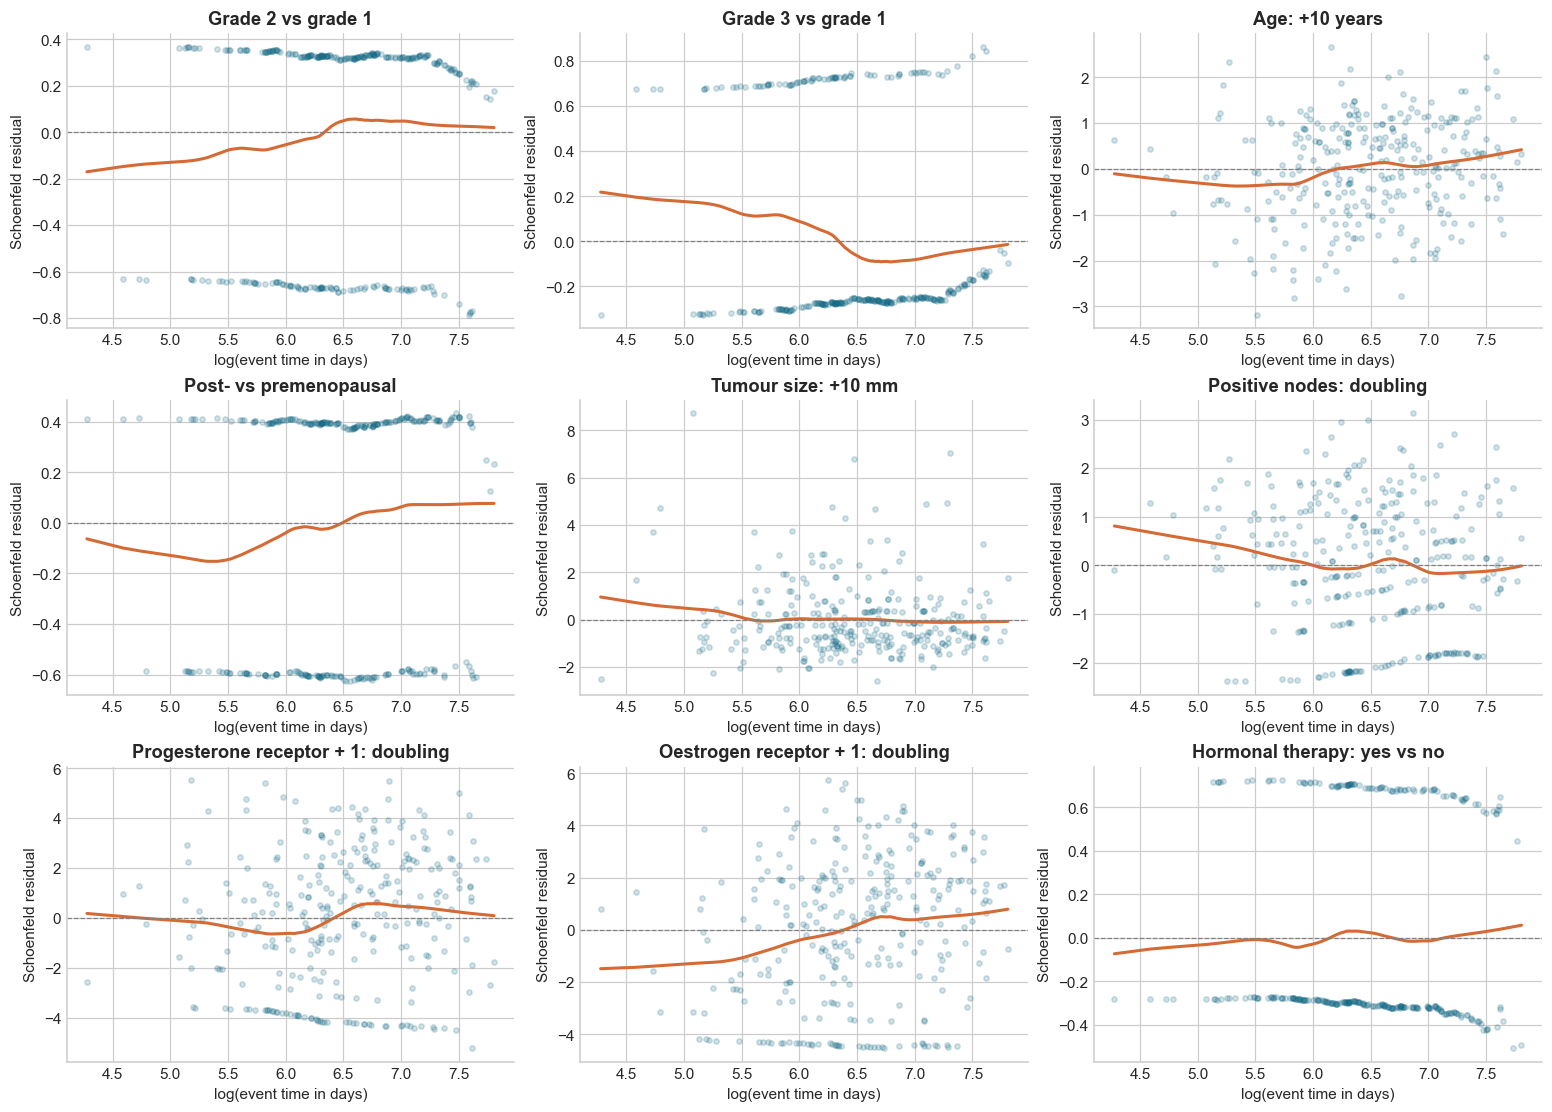

In [12]:
schoenfeld = np.asarray(fit.schoenfeld_residuals)
event_mask = model_data.status.eq(1).to_numpy()
event_logtime = np.log(model_data.loc[event_mask, 'rfstime'].to_numpy())
fig, axes = plt.subplots(3, 3, figsize=(14, 10), constrained_layout=True)
for j, (ax, column) in enumerate(zip(axes.flat, X.columns)):
    residual = schoenfeld[event_mask, j]
    valid = np.isfinite(residual) & np.isfinite(event_logtime)
    x, y = event_logtime[valid], residual[valid]
    ax.scatter(x, y, s=12, alpha=0.2, color='#176B87')
    trend = lowess(y, x, frac=0.55, it=0, return_sorted=True)
    ax.plot(trend[:, 0], trend[:, 1], color='#D56A35', linewidth=2)
    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8)
    ax.set(title=term_labels.get(column, column), xlabel='log(event time in days)',
           ylabel='Schoenfeld residual')
plt.show()

As a second visual check, approximately parallel log-minus-log KM curves support
a constant group hazard ratio. These are **unadjusted** comparisons and can look
different from the adjusted residual diagnostics. Intersections or nonparallel
curves motivate further investigation, not an automatic accept/reject decision.

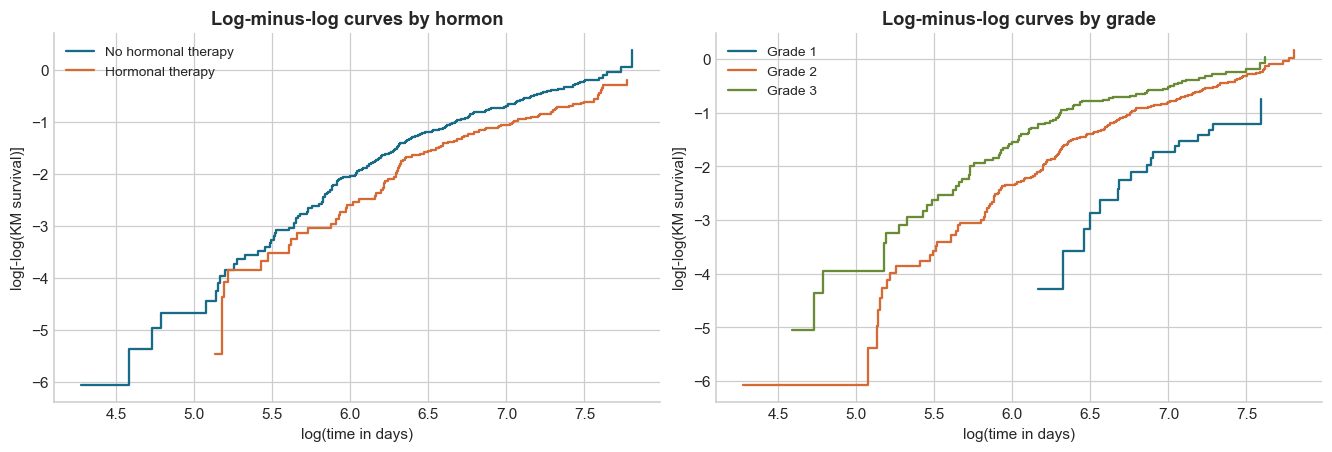

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, column in zip(axes, ['hormon', 'grade']):
    for (value, label), color in zip(category_maps[column].items(), colors):
        group = df.loc[df[column].eq(value)]
        sf = SurvfuncRight(group.rfstime, group.status)
        valid = (sf.surv_prob > 0) & (sf.surv_prob < 1)
        ax.step(np.log(sf.surv_times[valid]), np.log(-np.log(sf.surv_prob[valid])),
                where='post', color=color, label=label)
    ax.set(title=f'Log-minus-log curves by {column}',
           xlabel='log(time in days)', ylabel='log[-log(KM survival)]')
    ax.legend(frameon=False, fontsize=9)
plt.show()

## 9. Sensitivity to modelling choices

**Functional form.** Compare the main model with a more flexible model containing
cubic B-splines (4 degrees of freedom each) for age and tumour size. All other
predictors and the analysed patients stay the same. The likelihood-ratio test
jointly checks the additional flexibility in those two terms. Lower AIC indicates
a better trade-off between in-sample fit and complexity, not externally validated
prediction. The log-node and log-receptor forms remain assumptions.

In [14]:
flex_formula = ('bs(age10, df=4, degree=3, include_intercept=False) + meno + '
                'bs(size10, df=4, degree=3, include_intercept=False) + '
                'C(grade, Treatment(reference=1)) + log2_nodes + '
                'log2_pgr1 + log2_er1 + hormon')
flex_design = dmatrix(flex_formula, model_data, return_type='dataframe', NA_action='raise')
X_flex = flex_design.drop(columns='Intercept')
cox_flex = PHReg(model_data.rfstime, X_flex, status=model_data.status,
                 ties='efron', missing='raise')
fit_flex = cox_flex.fit(disp=0, maxiter=200, tol=1e-9)
flex_score = float(np.max(np.abs(cox_flex.score(fit_flex.params))))
if not np.isfinite(fit_flex.params).all() or flex_score > 1e-5:
    raise RuntimeError('Flexible model did not converge adequately.')
lr_statistic = float(2 * (fit_flex.llf - fit.llf))
lr_df = X_flex.shape[1] - X.shape[1]
lr_pvalue = float(chi2.sf(max(0, lr_statistic), lr_df))
model_comparison = pd.DataFrame({
    'Model': ['Main: linear age and size', 'Flexible: age and size splines'],
    'Coefficients': [X.shape[1], X_flex.shape[1]],
    'Partial log likelihood': [fit.llf, fit_flex.llf],
    'Partial AIC': [-2 * fit.llf + 2 * X.shape[1],
                    -2 * fit_flex.llf + 2 * X_flex.shape[1]],
})
display(model_comparison.round(3))
print(f'Joint added-flexibility LR test: chi-square={lr_statistic:.3f}, '
      f'df={lr_df}, exploratory p={lr_pvalue:.4g}')

,Model,Coefficients,Partial log likelihood,Partial AIC
0,Main: linear age and size,9,-1721.317,3460.634
1,Flexible: age and size splines,15,-1707.136,3444.272


Joint added-flexibility LR test: chi-square=28.362, df=6, exploratory p=8.029e-05


These curves show what the added flexibility changes. Each compares the hazard
at a given age or size with the hazard at that variable's median, keeping the
other predictors fixed. Shading gives pointwise 95% CIs for the spline contrast.
The plotted range is the 1st–99th percentile to avoid stretching the axes across
sparse extremes. The curves are relative hazards, not survival probabilities,
and both models still assume effects are constant over follow-up time.

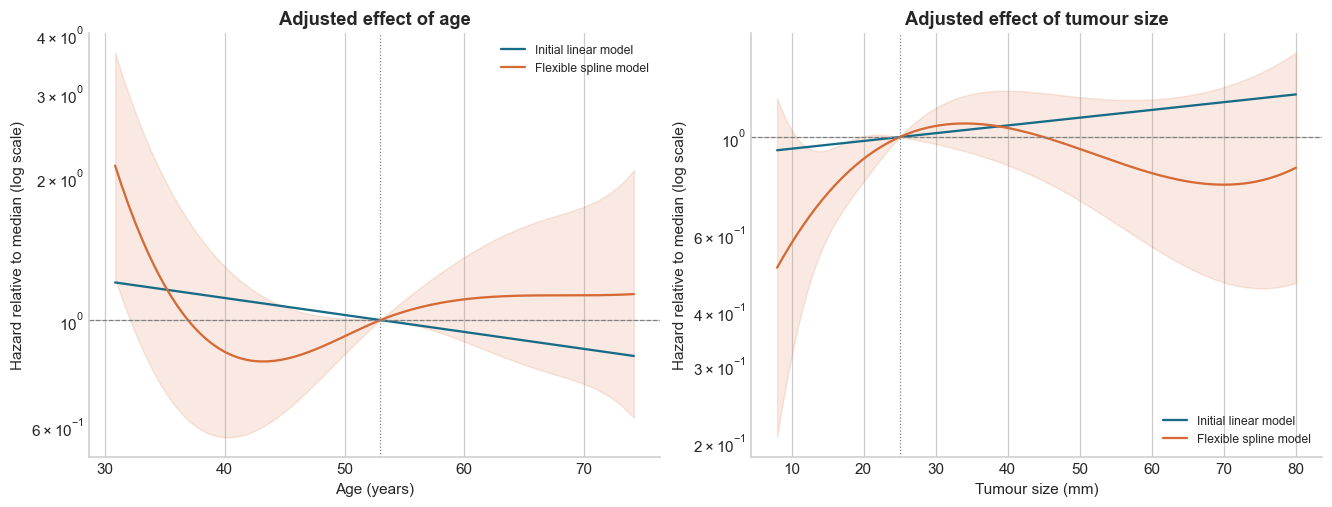

In [15]:
reference = model_data.median().to_frame().T

def transformed_design(info, data, columns):
    matrix = build_design_matrices([info], data, return_type='dataframe')[0]
    return matrix.loc[:, columns].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, column, label in zip(axes, ['age10', 'size10'], ['Age (years)', 'Tumour size (mm)']):
    grid = np.linspace(*model_data[column].quantile([0.01, 0.99]), 160)
    new_data = pd.concat([reference] * len(grid), ignore_index=True)
    new_data[column] = grid
    for name, result, info, columns, color in [
        ('Initial linear model', fit, design.design_info, X.columns, '#176B87'),
        ('Flexible spline model', fit_flex, flex_design.design_info, X_flex.columns, '#D56A35'),
    ]:
        contrast = (transformed_design(info, new_data, columns)
                    - transformed_design(info, reference, columns))
        log_hr = contrast @ result.params
        se = np.sqrt(np.maximum(0, np.einsum('ij,jk,ik->i', contrast,
                                           result.cov_params(), contrast)))
        ax.plot(grid * 10, np.exp(log_hr), label=name, color=color)
        if name == 'Flexible spline model':
            ax.fill_between(grid * 10, np.exp(log_hr - 1.96 * se),
                            np.exp(log_hr + 1.96 * se), color=color, alpha=0.14)
    ax.axhline(1, color='grey', linestyle='--', linewidth=0.8)
    ax.axvline(float(reference[column].iloc[0] * 10), color='grey', linestyle=':', linewidth=0.8)
    ax.set_yscale('log')
    ax.set(xlabel=label, ylabel='Hazard relative to median (log scale)',
           title=f'Adjusted effect of {label.split(" (")[0].lower()}')
    ax.legend(frameon=False, fontsize=8)
plt.show()

In [16]:
grade_terms = [c for c in X.columns if c.startswith('C(grade,')]
X_strat = X.drop(columns=grade_terms)
cox_strat = PHReg(model_data.rfstime, X_strat, status=model_data.status,
                  strata=model_data.grade, ties='efron', missing='raise')
fit_strat = cox_strat.fit(disp=0, maxiter=200, tol=1e-9)
strat_score = float(np.max(np.abs(cox_strat.score(fit_strat.params))))
if not np.isfinite(fit_strat.params).all() or strat_score > 1e-5:
    raise RuntimeError('Grade-stratified model did not converge adequately.')
therapy_sensitivity = []
for name, result, columns in [
    ('Main model', fit, X.columns),
    ('Flexible age and size', fit_flex, X_flex.columns),
    ('Separate baseline hazard by grade', fit_strat, X_strat.columns),
]:
    index = list(columns).index('hormon')
    bounds = np.exp(result.conf_int()[index])
    therapy_sensitivity.append({
        'Model': name, 'Therapy HR': np.exp(result.params[index]),
        '95% lower': bounds[0], '95% upper': bounds[1],
    })
display(pd.DataFrame(therapy_sensitivity).round(3))

,Model,Therapy HR,95% lower,95% upper
0,Main model,0.680,0.528,0.876
1,Flexible age and size,0.637,0.493,0.822
2,Separate baseline hazard by grade,0.675,0.524,0.870


## 10. Findings and next questions

The following summary is calculated from the file and fitted models, so it updates
when the notebook is rerun. The main model is an exploratory starting point; the
sensitivity analyses and diagnostic plots determine what needs refinement.

In [17]:
five_year = survival_at_times.loc[survival_at_times.Year.eq(5)].iloc[0]
nodes_row = hazard_ratios.loc[hazard_ratios.Term.eq('log2_nodes')].iloc[0]
flexibility_text = (
    'The added age/size spline terms show evidence of improved fit at the conventional '
    '5% level; investigate the shapes before adopting the simple model.'
    if lr_pvalue < 0.05 else
    'The joint spline comparison does not show strong evidence for additional '
    'age/size flexibility at the conventional 5% level; this does not prove linearity.'
)
display(Markdown(f"""
- **Cohort:** {n} patients, {events} recurrence/death events and {n - events} censored records;
  no missing values or repeated patient IDs in the supplied file.
- **Five-year recurrence-free survival:** {five_year['Survival']:.1%}
  (pointwise 95% CI {five_year['95% lower']:.1%}–{five_year['95% upper']:.1%});
  {int(five_year['At risk just before time'])} patients remain at risk just before five years.
- **Hormonal therapy:** adjusted HR {therapy_row['HR']:.2f}
  (95% CI {therapy_row['95% lower']:.2f}–{therapy_row['95% upper']:.2f}) in the main model.
- **Positive lymph nodes:** adjusted HR {nodes_row['HR']:.2f} per doubling
  (95% CI {nodes_row['95% lower']:.2f}–{nodes_row['95% upper']:.2f}).
- **Functional form:** {flexibility_text}
- **Proportional hazards:** the graphical checks raise concerns for several
  predictors; the constant HRs should remain exploratory pending further checks.
"""))


- **Cohort:** 686 patients, 299 recurrence/death events and 387 censored records;
  no missing values or repeated patient IDs in the supplied file.
- **Five-year recurrence-free survival:** 49.2%
  (pointwise 95% CI 44.6%–53.6%);
  121 patients remain at risk just before five years.
- **Hormonal therapy:** adjusted HR 0.68
  (95% CI 0.53–0.88) in the main model.
- **Positive lymph nodes:** adjusted HR 1.40 per doubling
  (95% CI 1.28–1.53).
- **Functional form:** The added age/size spline terms show evidence of improved fit at the conventional 5% level; investigate the shapes before adopting the simple model.
- **Proportional hazards:** the graphical checks raise concerns for several
  predictors; the constant HRs should remain exploratory pending further checks.


The findings from these 686 patients are:

- **Estimated five-year recurrence-free survival was 49.2%** (95% CI: 44.6–53.6%). The endpoint includes either recurrence or death.
- **More positive lymph nodes were associated with poorer outcomes.** In the initial adjusted model, doubling the node count corresponded to about a **40% higher hazard**.
- **Higher-grade tumours had poorer outcomes.** Grades 2 and 3 had approximately **1.7–1.8 times the hazard** of grade 1.
- **Hormonal therapy was associated with better outcomes.** Its adjusted hazard ratio stayed around **0.64–0.68** across the models—approximately a 32–36% lower instantaneous event rate.
- **Higher progesterone receptor levels were associated with a lower hazard.**
- **Age and/or tumour size needed a curved relationship with the outcome.** The spline comparison supported that additional flexibility, although it did not identify which variable drove the improvement.

These are **exploratory associations**. The residual plots suggest some effects may change during follow-up, so the exact hazard ratios need further checking before being reported as definitive estimates.

### References

- [GBSG variable definitions and cohort description, survival package](https://github.com/therneau/survival/blob/master/man/gbsg.Rd)
- [statsmodels Cox PH regression](https://www.statsmodels.org/stable/generated/statsmodels.duration.hazard_regression.PHReg.html)
- [statsmodels Kaplan–Meier estimator](https://www.statsmodels.org/stable/generated/statsmodels.duration.survfunc.SurvfuncRight.html)
- [statsmodels Schoenfeld residuals](https://www.statsmodels.org/stable/generated/statsmodels.duration.hazard_regression.PHRegResults.schoenfeld_residuals.html)